JKO VS. EXACT HEAT EQUATION

Initial sigma = 1.0
Final time = 2.0

  tau  Steps  Final_JKO_Variance  Exact_Final_Variance  Final_Error  Maximum_Error
0.500      4            4.654848                   5.0     0.345152       0.345152
0.250      8            4.814548                   5.0     0.185452       0.185452
0.100     20            4.922209                   5.0     0.077791       0.077791
0.050     40            4.960449                   5.0     0.039551       0.039551
0.025     80            4.980055                   5.0     0.019945       0.019945

AUTOMATIC VERIFICATION
PASS: JKO variance is below the exact heat variance for every tested finite time step.
PASS: Final error decreases as tau decreases.

Maximum variance-increment identity error = 2.1094237467877974e-15
PASS: Variance increment identity is verified.

CONVERGENCE TABLE

  tau  Steps  Final_JKO_Variance  Exact_Final_Variance  Final_Error  Maximum_Error  Observed_Order
0.500      4            4.654848            

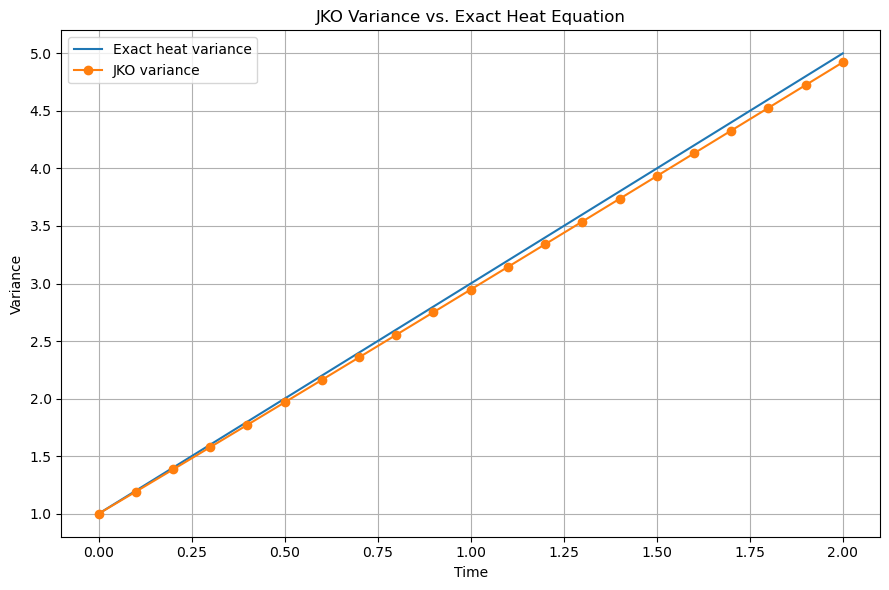

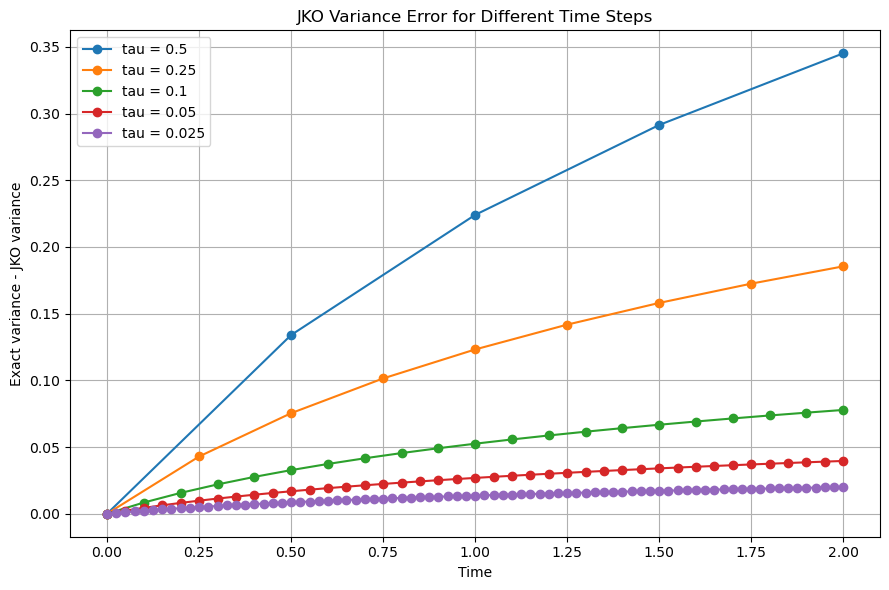

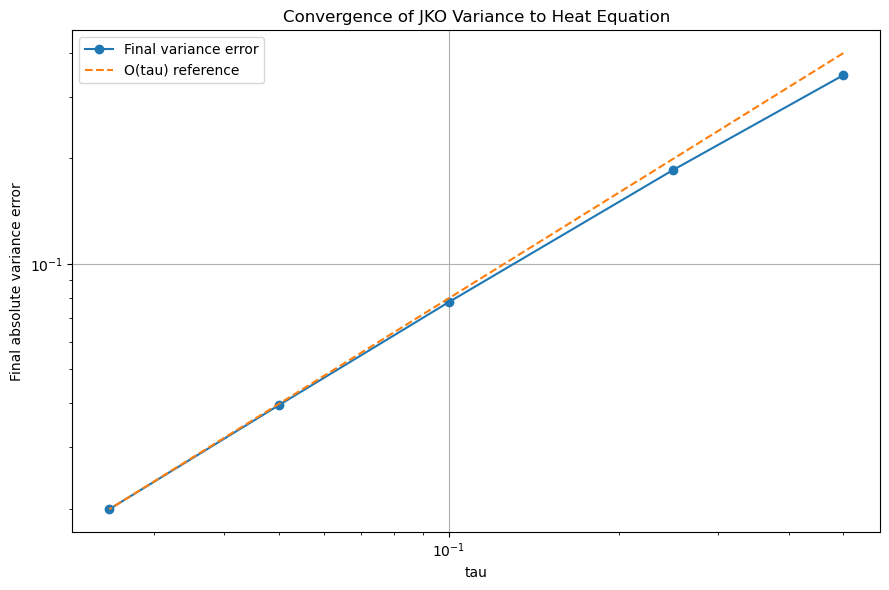


FINAL RESULT

Exact heat variance:
sigma^2(t) = sigma0^2 + 2t

JKO variance converges to the exact heat variance as tau -> 0.

The observed global convergence is approximately first order in tau.


In [2]:
# ============================================================
# HOMEWORK 4.2 - PART IV
# JKO VS. EXACT HEAT EQUATION
# STANDALONE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

sigma0 = 1.0

T = 2.0


tau_values = np.array([
    0.5,
    0.25,
    0.1,
    0.05,
    0.025
])


# ============================================================
# JKO UPDATE
# ============================================================

def jko_update(
    sigma_k,
    tau
):

    return (

        sigma_k

        +

        np.sqrt(

            sigma_k**2

            +

            4.0
            *
            tau
        )

    ) / 2.0


# ============================================================
# EXACT HEAT VARIANCE
# ============================================================

def exact_variance(
    t,
    sigma0
):

    return (

        sigma0**2

        +

        2.0
        *
        t
    )


# ============================================================
# RUN ONE JKO TRAJECTORY
# ============================================================

def run_jko(
    sigma0,
    tau,
    T
):

    number_of_steps = int(
        round(
            T / tau
        )
    )


    times = np.arange(
        number_of_steps + 1
    ) * tau


    sigma_values = np.zeros(
        number_of_steps + 1
    )


    sigma_values[0] = sigma0


    for k in range(
        number_of_steps
    ):

        sigma_values[
            k + 1
        ] = jko_update(

            sigma_values[k],

            tau
        )


    variances = (

        sigma_values**2
    )


    exact_variances = exact_variance(

        times,

        sigma0
    )


    errors = (

        exact_variances

        -

        variances
    )


    return (
        times,
        sigma_values,
        variances,
        exact_variances,
        errors
    )


# ============================================================
# SUMMARY FOR ALL tau VALUES
# ============================================================

summary_rows = []


all_runs = {}


for tau in tau_values:

    (
        times,
        sigmas,
        variances,
        exact_variances,
        errors

    ) = run_jko(

        sigma0,
        tau,
        T
    )


    all_runs[tau] = {

        "times":
            times,

        "sigmas":
            sigmas,

        "variances":
            variances,

        "exact_variances":
            exact_variances,

        "errors":
            errors

    }


    final_variance = (
        variances[-1]
    )


    final_exact_variance = (
        exact_variances[-1]
    )


    final_error = (

        final_exact_variance

        -

        final_variance
    )


    max_error = np.max(
        np.abs(
            errors
        )
    )


    summary_rows.append({

        "tau":
            tau,

        "Steps":
            len(times) - 1,

        "Final_JKO_Variance":
            final_variance,

        "Exact_Final_Variance":
            final_exact_variance,

        "Final_Error":
            final_error,

        "Maximum_Error":
            max_error

    })


summary_df = pd.DataFrame(
    summary_rows
)


# ============================================================
# PRINT SUMMARY
# ============================================================

print("=" * 90)

print(
    "JKO VS. EXACT HEAT EQUATION"
)

print("=" * 90)

print()

print(
    "Initial sigma =",
    sigma0
)

print(
    "Final time =",
    T
)

print()

print(
    summary_df.to_string(
        index=False
    )
)


# ============================================================
# BASIC CHECKS
# ============================================================

print()

print("=" * 90)

print(
    "AUTOMATIC VERIFICATION"
)

print("=" * 90)


# Every final JKO variance should be below exact
assert np.all(

    summary_df[
        "Final_JKO_Variance"
    ]

    <

    summary_df[
        "Exact_Final_Variance"
    ]
)


print(
    "PASS: JKO variance is below the exact heat variance "
    "for every tested finite time step."
)


# Error should decrease as tau decreases
final_errors = summary_df[
    "Final_Error"
].to_numpy()


assert np.all(

    np.diff(
        final_errors
    )

    <
    0
)


print(
    "PASS: Final error decreases as tau decreases."
)


# ============================================================
# CHECK ONE-STEP VARIANCE IDENTITY
#
# sigma_{k+1}^2 - sigma_k^2
#
# =
#
# 2 tau - tau^2 / sigma_{k+1}^2
# ============================================================

max_increment_identity_error = 0.0


for tau in tau_values:

    sigmas = all_runs[tau][
        "sigmas"
    ]


    for k in range(
        len(sigmas) - 1
    ):

        sigma_k = sigmas[k]

        sigma_next = sigmas[
            k + 1
        ]


        left = (

            sigma_next**2

            -

            sigma_k**2
        )


        right = (

            2.0
            *
            tau

            -

            tau**2

            /

            sigma_next**2
        )


        identity_error = abs(

            left
            -
            right
        )


        max_increment_identity_error = max(

            max_increment_identity_error,

            identity_error
        )


print()

print(
    "Maximum variance-increment identity error =",
    max_increment_identity_error
)


assert max_increment_identity_error < 1e-12


print(
    "PASS: Variance increment identity is verified."
)


# ============================================================
# COMPUTE OBSERVED CONVERGENCE ORDER
# ============================================================

orders = [
    np.nan
]


for i in range(
    1,
    len(summary_df)
):

    tau_old = summary_df.loc[
        i - 1,
        "tau"
    ]

    tau_new = summary_df.loc[
        i,
        "tau"
    ]


    error_old = summary_df.loc[
        i - 1,
        "Final_Error"
    ]

    error_new = summary_df.loc[
        i,
        "Final_Error"
    ]


    order = (

        np.log(
            error_old
            /
            error_new
        )

        /

        np.log(
            tau_old
            /
            tau_new
        )
    )


    orders.append(
        order
    )


summary_df[
    "Observed_Order"
] = orders


print()

print("=" * 90)

print(
    "CONVERGENCE TABLE"
)

print("=" * 90)

print()

print(
    summary_df.to_string(
        index=False
    )
)


print()

print(
    "Observed orders approach 1 as tau decreases."
)


# ============================================================
# PLOT 1:
# REPRESENTATIVE JKO TRAJECTORY VS EXACT HEAT VARIANCE
# ============================================================

tau_example = 0.1


run = all_runs[
    tau_example
]


plt.figure(
    figsize=(9, 6)
)


plt.plot(
    run[
        "times"
    ],
    run[
        "exact_variances"
    ],
    label="Exact heat variance"
)


plt.plot(
    run[
        "times"
    ],
    run[
        "variances"
    ],
    marker="o",
    label="JKO variance"
)


plt.xlabel(
    "Time"
)

plt.ylabel(
    "Variance"
)

plt.title(
    "JKO Variance vs. Exact Heat Equation"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part4_jko_vs_heat.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 2:
# ERROR VS TIME FOR SEVERAL tau VALUES
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for tau in tau_values:

    run = all_runs[
        tau
    ]


    plt.plot(
        run[
            "times"
        ],
        run[
            "errors"
        ],
        marker="o",
        label=f"tau = {tau}"
    )


plt.xlabel(
    "Time"
)

plt.ylabel(
    "Exact variance - JKO variance"
)

plt.title(
    "JKO Variance Error for Different Time Steps"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part4_error_vs_time.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 3:
# FINAL ERROR VS tau
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.loglog(
    summary_df[
        "tau"
    ],
    summary_df[
        "Final_Error"
    ],
    marker="o",
    label="Final variance error"
)


# First-order reference line
reference_constant = (

    summary_df[
        "Final_Error"
    ].iloc[-1]

    /

    summary_df[
        "tau"
    ].iloc[-1]
)


reference_line = (

    reference_constant

    *

    summary_df[
        "tau"
    ]
)


plt.loglog(
    summary_df[
        "tau"
    ],
    reference_line,
    linestyle="--",
    label="O(tau) reference"
)


plt.xlabel(
    "tau"
)

plt.ylabel(
    "Final absolute variance error"
)

plt.title(
    "Convergence of JKO Variance to Heat Equation"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part4_convergence.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL RESULT
# ============================================================

print()

print("=" * 90)

print(
    "FINAL RESULT"
)

print("=" * 90)

print()

print(
    "Exact heat variance:"
)

print(
    "sigma^2(t) = sigma0^2 + 2t"
)

print()

print(
    "JKO variance converges to the exact heat variance "
    "as tau -> 0."
)

print()

print(
    "The observed global convergence is approximately "
    "first order in tau."
)